# Guía de Trabajo: ACP y Clustering
---

## Objetivo

Aplicar ACP a cinco data sets de acceso públicos para explorar la estructura interna de los datos, reducir la dimensionalidad y visualizar patrones

| Dataset   | Descripción                                           | Enlace                                                                                 |
| --        | --                                                    | --                                                                                     |
| Wine      | Composición química de vinos italianos                | [Wine](https://archive.ics.uci.edu/dataset/109/wine)                                   |
| Iris      | Medidas de sépalos y pétalos de tres especies de Iris | [Iris](https://archive.ics.uci.edu/dataset/53/iris)                                    |
| USArrests | Estadísticas de arrestos en EE.UU.                    | [Housing](https://github.com/ageron/handson-ml2/tree/master/datasets/housing)          |
| Human Activity Recognition | Datos de sensores de smartphones     | [Human](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) |
| Olive Oil | Composición química de aceites de oliva               | [Olive Oil](https://service.tib.eu/ldmservice/dataset/olive-oil)                       |

## Wine

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

In [3]:
# fetch dataset 
wine = fetch_ucirepo(id=109) 

In [4]:
# data (as pandas dataframes) 
X = wine.data.features # datos numéricos
y = wine.data.targets  # etiqueta

In [5]:
# metadata 
wine.metadata 

{'uci_id': 109,
 'name': 'Wine',
 'repository_url': 'https://archive.ics.uci.edu/dataset/109/wine',
 'data_url': 'https://archive.ics.uci.edu/static/public/109/data.csv',
 'abstract': 'Using chemical analysis to determine the origin of wines',
 'area': 'Physics and Chemistry',
 'tasks': ['Classification'],
 'characteristics': ['Tabular'],
 'num_instances': 178,
 'num_features': 13,
 'feature_types': ['Integer', 'Real'],
 'demographics': [],
 'target_col': ['class'],
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 1992,
 'last_updated': 'Mon Aug 28 2023',
 'dataset_doi': '10.24432/C5PC7J',
 'creators': ['Stefan Aeberhard', 'M. Forina'],
 'intro_paper': {'ID': 246,
  'type': 'NATIVE',
  'title': 'Comparative analysis of statistical pattern recognition methods in high dimensional settings',
  'authors': 'S. Aeberhard, D. Coomans, O. Vel',
  'venue': 'Pattern Recognition',
  'year': 1994,
  'journal': None,
  'DOI': '10.1016/003

In [6]:
# variable information 
wine.variables

,name,role,type,demographic,description,units,missing_values
0,class,Target,Categorical,None,None,None,no
1,Alcohol,Feature,Continuous,None,None,None,no
2,Malicacid,Feature,Continuous,None,None,None,no
3,Ash,Feature,Continuous,None,None,None,no
4,Alcalinity_of_ash,Feature,Continuous,None,None,None,no
5,Magnesium,Feature,Integer,None,None,None,no
6,Total_phenols,Feature,Continuous,None,None,None,no
7,Flavanoids,Feature,Continuous,None,None,None,no
8,Nonflavanoid_phenols,Feature,Continuous,None,None,None,no
9,Proanthocyanins,Feature,Continuous,None,None,None,no


In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
import plotly.figure_factory as ff

In [8]:
X

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [9]:
# Estandarizar las variables numéricas
scaler = StandardScaler()
Xscaled = scaler.fit_transform(X) # resta a cada variable la media de su grupo y lo divide por el desvio estándar

### PCA

In [10]:
# Aplicar PCA
componentes = 7
pca = PCA(n_components=componentes)
Xpca = pca.fit_transform(Xscaled)

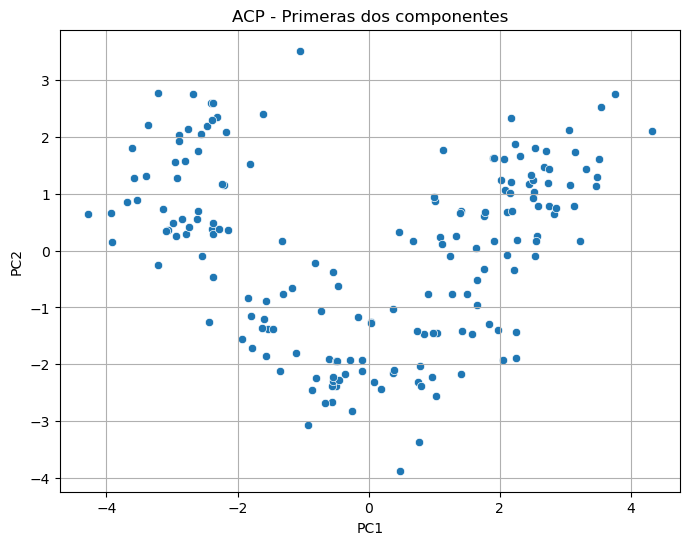

In [11]:
# Visualizar
plt.figure(figsize=(8,6))
sns.scatterplot(x=Xpca[:,0], y=Xpca[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("ACP - Primeras dos componentes")
plt.grid(True)
plt.show()

* Se busca una combinación lineal que maximice la varianza
* En PC1 me recoge la mayor varianza
* Luego busco una componente ortogonal a PC1 que me proyecte sobre PC2 y tambien que maximice la varianza

In [12]:
# Autovalores: miden la varianza
eigenvalues = pca.explained_variance_
eigenvalues_df = pd.DataFrame(eigenvalues, columns=['Autovalores'], index=[f'PC{i+1}' for i in range(componentes)])
eigenvalues_df

,Autovalores
PC1,4.732437
PC2,2.511081
PC3,1.454242
PC4,0.924166
PC5,0.858049
PC6,0.645282
PC7,0.554141


* ¿Cómo se decide con cuantas componentes me quedo?
    * Me quedo con todas las componentes que tengan **autovalores mayores a 1**. En este caso con 3
    * Lo ideal es quedarse con 2 componentes que uno lo proyecta en el plano 

In [13]:
# Porcentaje de varianza explicada
explained_variance_ratio = pca.explained_variance_ratio_ * 100
explained_variance_ratio_df = pd.DataFrame(explained_variance_ratio, columns=['% Varianza'], index=[f'PC{i+1}' for i in range(componentes)])
explained_variance_ratio_df

,% Varianza
PC1,36.198848
PC2,19.207490
PC3,11.123631
PC4,7.069030
PC5,6.563294
PC6,4.935823
PC7,4.238679


In [14]:
# Varianza acumulada
cumulative_variance = np.cumsum(explained_variance_ratio)
cumulative_variance_df = pd.DataFrame(cumulative_variance, columns=['Varianza Acumulada'], index=[f'PC{i+1}' for i in range(componentes)])
cumulative_variance_df

,Varianza Acumulada
PC1,36.198848
PC2,55.406338
PC3,66.529969
PC4,73.598999
PC5,80.162293
PC6,85.098116
PC7,89.336795


* Con 2 componentes explico 55.4% de la varianza (es muy bajo)
* Con 3 componentes explico 66.52% de la varianza
* Con 4 componentes explico 73.59% de la varianza (estaria bien, mas de 70%)
* **Lo que dejo es información que pierdo**

In [15]:
# Autovectores: miden los coeficientes
eigenvectors = pca.components_
eigenvectors_df = pd.DataFrame(eigenvectors, columns=X.columns, index=[f'PC{i+1}' for i in range(componentes)])
eigenvectors_df

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
PC1,0.144329,-0.245188,-0.002051,-0.239320,0.141992,0.394661,0.422934,-0.298533,0.313429,-0.088617,0.296715,0.376167,0.286752
PC2,0.483652,0.224931,0.316069,-0.010591,0.299634,0.065040,-0.003360,0.028779,0.039302,0.529996,-0.279235,-0.164496,0.364903
PC3,-0.207383,0.089013,0.626224,0.612080,0.130757,0.146179,0.150682,0.170368,0.149454,-0.137306,0.085222,0.166005,-0.126746
PC4,-0.017856,0.536890,-0.214176,0.060859,-0.351797,0.198068,0.152295,-0.203301,0.399057,0.065926,-0.427771,0.184121,-0.232071
PC5,-0.265664,0.035214,-0.143025,0.066103,0.727049,-0.149318,-0.109026,-0.500703,0.136860,-0.076437,-0.173615,-0.101161,-0.157869
PC6,0.213539,0.536814,0.154475,-0.100825,0.038144,-0.084122,-0.018920,-0.258594,-0.533795,-0.418644,0.105983,0.265851,0.119726
PC7,-0.056396,0.420524,-0.149171,-0.286969,0.322883,-0.027925,-0.060685,0.595447,0.372139,-0.227712,0.232076,-0.044764,0.076805


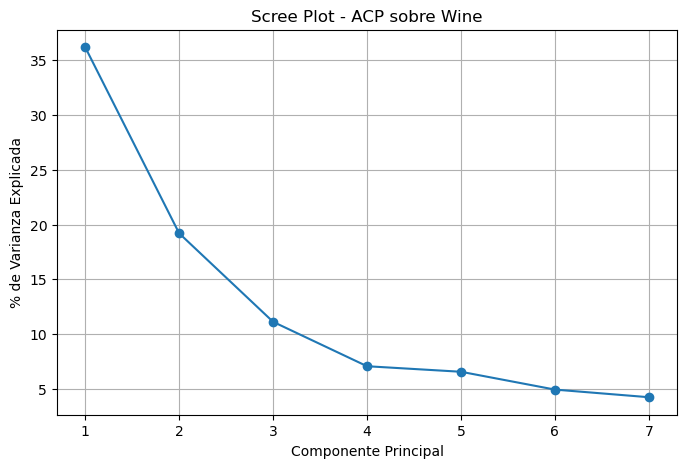

In [16]:
# Scree Plot
plt.figure(figsize=(8,5))
plt.plot(range(1, len(eigenvalues)+1), explained_variance_ratio, marker='o')
plt.title('Scree Plot - ACP sobre Wine')
plt.xlabel('Componente Principal')
plt.ylabel('% de Varianza Explicada')
plt.grid(True)
plt.show()

* **Método del codo**: se busca el número de componente donde se estabiliza la varianza. En este caso 3 ó 4 

In [17]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings, index=X.columns, columns=[f'PC{i+1}' for i in range(componentes)])
loadings_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Alcohol,0.313977,0.766413,-0.250087,-0.017166,-0.246087,0.171534,-0.041982
Malicacid,-0.533385,0.356434,0.107342,0.516132,0.032619,0.431220,0.313041
Ash,-0.004462,0.500855,0.755176,-0.205895,-0.132486,0.124089,-0.111044
Alcalinity_of_ash,-0.520622,-0.016782,0.738120,0.058506,0.061232,-0.080992,-0.213622
Magnesium,0.308892,0.474812,0.157682,-0.338195,0.673472,0.030641,0.240357
Total_phenols,0.858552,0.103064,0.176280,0.190410,-0.138315,-0.067575,-0.020788
Flavanoids,0.920058,-0.005324,0.181710,0.146406,-0.100992,-0.015198,-0.045174
Nonflavanoid_phenols,-0.649434,0.045605,0.205450,-0.195440,-0.463806,-0.207727,0.443255
Proanthocyanins,0.681840,0.062279,0.180230,0.383627,0.126775,-0.428795,0.277023
Color_intensity,-0.192778,0.839852,-0.165580,0.063377,-0.070804,-0.336295,-0.169510


In [18]:
# cos²: cuadrado de las correlaciones entre variables y componentes
cos2 = (eigenvectors**2) * eigenvalues[:, np.newaxis]
cos2_df = pd.DataFrame(cos2.T, index=X.columns, columns=[f"PC{i+1}" for i in range(componentes)])
cos2_df

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Alcohol,0.098581,0.587389,0.062543,0.000295,0.060559,0.029424,0.001762
Malicacid,0.284500,0.127045,0.011522,0.266392,0.001064,0.185950,0.097995
Ash,0.000020,0.250856,0.570290,0.042393,0.017552,0.015398,0.012331
Alcalinity_of_ash,0.271047,0.000282,0.544821,0.003423,0.003749,0.006560,0.045634
Magnesium,0.095414,0.225446,0.024864,0.114376,0.453564,0.000939,0.057771
Total_phenols,0.737111,0.010622,0.031075,0.036256,0.019131,0.004566,0.000432
Flavanoids,0.846507,0.000028,0.033019,0.021435,0.010199,0.000231,0.002041
Nonflavanoid_phenols,0.421764,0.002080,0.042210,0.038197,0.215116,0.043151,0.196475
Proanthocyanins,0.464905,0.003879,0.032483,0.147170,0.016072,0.183865,0.076742
Color_intensity,0.037163,0.705351,0.027417,0.004017,0.005013,0.113094,0.028734


In [19]:
# La suma de los cosenos cuadrados de una misma componente es igual al autovalor
np.sum(cos2_df.PC1), eigenvalues_df[:1]

(4.732436977583592,
      Autovalores
 PC1     4.732437)

In [20]:
# Contribución de cada variable a cada componente (en %)
contrib = (cos2.T * pca.explained_variance_ratio_ * 100).T
contrib_df = pd.DataFrame(contrib, index=[f'PC{i+1}' for i in range(componentes)], columns=X.columns)
contrib_df

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
PC1,3.568529,10.298561,0.000721,9.811582,3.453883,26.682571,30.642585,15.267382,16.829038,1.345274,15.081944,24.240520,14.086179
PC2,11.282270,2.440224,4.818309,0.005410,4.330256,0.204026,0.000544,0.039948,0.074500,13.548025,3.760724,1.305098,6.422229
PC3,0.695709,0.128171,6.343698,6.060383,0.276575,0.345663,0.367287,0.469526,0.361327,0.304975,0.117486,0.445783,0.259867
PC4,0.002083,1.883132,0.299674,0.024197,0.808524,0.256295,0.151523,0.270016,1.040348,0.028394,1.195455,0.221470,0.351845
PC5,0.397464,0.006983,0.115202,0.024608,2.976875,0.125563,0.066941,1.411868,0.105484,0.032903,0.169748,0.057631,0.140355
PC6,0.145232,0.917818,0.076002,0.032377,0.004634,0.022539,0.001140,0.212984,0.907526,0.558212,0.035775,0.225106,0.045654
PC7,0.007471,0.415368,0.052266,0.193429,0.244874,0.001832,0.008650,0.832795,0.325284,0.121793,0.126506,0.004707,0.013856


In [21]:
# Círculo de correlación
plt.figure(figsize=(6,6))
for i, var in enumerate(variables):
    plt.arrow(0, 0, eigenvectors[0, i], eigenvectors[1, i],
              head_width=0.03, head_length=0.03, fc='blue', ec='blue')
    plt.text(eigenvectors[0, i]*1.1, eigenvectors[1, i]*1.1, var, color='black')

circle = plt.Circle((0, 0), 1, color='gray', fill=False)
plt.gca().add_artist(circle)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Círculo de correlación")
plt.grid()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

NameError: name 'variables' is not defined

<Figure size 600x600 with 0 Axes>

* dos vectores **pegados** significa que **están altamente correlacionados** (total phenols, havanoids, ...) , (Alcohol, Proline, ...)
* dos vectores formando un ángulo de 90% **no están altamente correlacionados** (Color_intensity y total phenols)
* dos vectores diametralmente opuestos significa que **no están correlacionados** (Malicacid y Hue)

* Todas las variables contribuyen un poquito, ya que ninguna llega al radio 1
* **Hue** contribuye 0.25 a PC1 (positivamente) y -0.25 a PC2 (negativamente). Son proyecciones (loadings)

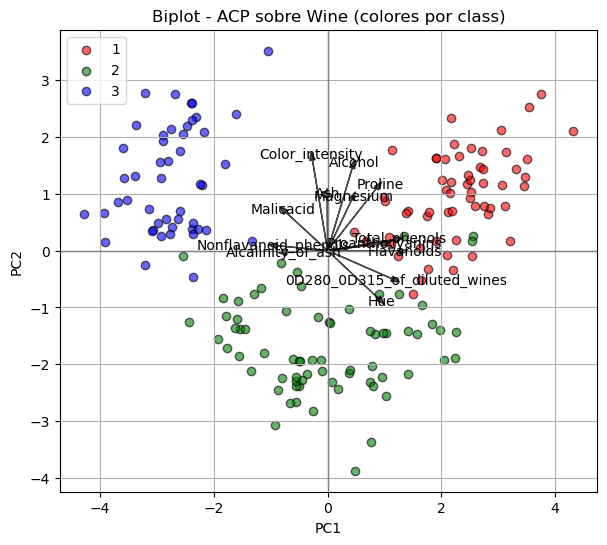

In [22]:
#Individuos (unidades experimentales) + variables

# Crear biplot con colores por especie
plt.figure(figsize=(8, 6))
class_unique = y['class'].unique()
colors = ['red', 'green', 'blue']

for clas, color in zip(class_unique, colors):
    idx = y['class'] == clas
    plt.scatter(Xpca[idx, 0], Xpca[idx, 1], label=clas, color=color, alpha=0.6, edgecolor='k')

# Graficar vectores de variables
variables = X.columns
for i in range(len(variables)):
    plt.arrow(0, 0, eigenvectors[0, i]*3, eigenvectors[1, i]*3,
              color='black', alpha=0.7, head_width=0.1)
    plt.text(eigenvectors[0, i]*3.2, eigenvectors[1, i]*3.2,
             variables[i], color='black', ha='center', va='center')

# Configurar gráfico
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Biplot - ACP sobre Wine (colores por class)")
plt.grid()
plt.axhline(0, color='gray', lw=1)
plt.axvline(0, color='gray', lw=1)
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### Clustering

In [23]:
# KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(Xpca)

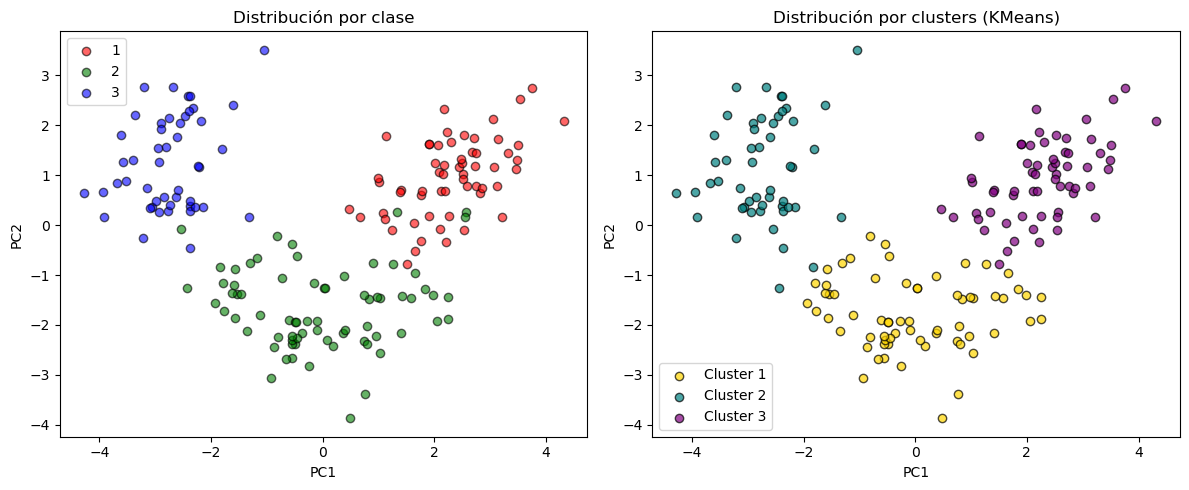

In [24]:
# Graficar
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
class_unique = y['class'].unique()
colors_class = ['red', 'green', 'blue']
colors_clusters = ['gold', 'teal', 'purple']

# Gráfico por clase
for clas, color in zip(class_unique, colors_class):
    idx = y['class'] == clas
    axs[0].scatter(Xpca[idx, 0], Xpca[idx, 1], label=clas, color=color, alpha=0.6, edgecolor='k')
axs[0].set_title("Distribución por clase")
axs[0].set_xlabel("PC1")
axs[0].set_ylabel("PC2")
axs[0].legend()

# Gráfico por cluster con leyenda
for cluster_id, color in enumerate(colors_clusters):
    idx = kmeans_labels == cluster_id
    axs[1].scatter(Xpca[idx, 0], Xpca[idx, 1], label=f"Cluster {cluster_id+1}", color=color, alpha=0.7, edgecolor='k')
axs[1].set_title("Distribución por clusters (KMeans)")
axs[1].set_xlabel("PC1")
axs[1].set_ylabel("PC2")
axs[1].legend()

plt.tight_layout()
plt.show()

## Iris

In [25]:
# fetch dataset 
iris = fetch_ucirepo(id=53)       # df = pd.readcsv("iris.csv")
                                  # df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
# data (as pandas dataframes) 
X = iris.data.features            # X = df.select_dtypes(include='number')
y = iris.data.targets

In [26]:
iris.metadata

{'uci_id': 53,
 'name': 'Iris',
 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris',
 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv',
 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n',
 'area': 'Biology',
 'tasks': ['Classification'],
 'characteristics': ['Tabular'],
 'num_instances': 150,
 'num_features': 4,
 'feature_types': ['Real'],
 'demographics': [],
 'target_col': ['class'],
 'index_col': None,
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 1936,
 'last_updated': 'Tue Sep 12 2023',
 'dataset_doi': '10.24432/C56C76',
 'creators': ['R. A. Fisher'],
 'intro_paper': {'ID': 191,
  'type': 'NATIVE',
  'title': 'The Iris data set: In search of the source of virginica',
  'authors': 'A. Unwin, K. Kleinman',
  'venue': 'Significance, 2021',
  'year': 2021,
  'journal': 'Significance, 2021',
  'DOI': '1740-9713.01589',
  'UR

In [27]:
iris.variables

,name,role,type,demographic,description,units,missing_values
0,sepal length,Feature,Continuous,None,None,cm,no
1,sepal width,Feature,Continuous,None,None,cm,no
2,petal length,Feature,Continuous,None,None,cm,no
3,petal width,Feature,Continuous,None,None,cm,no
4,class,Target,Categorical,None,"class of iris plant: Iris Setosa, Iris Versico...",None,no


In [28]:
X

,sepal length,sepal width,petal length,petal width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [29]:
# Estandarizar
scaler = StandardScaler()
Xscaled = scaler.fit_transform(X)

### PCA

In [30]:
# Aplicar PCA
pca = PCA(n_components=2)
Xpca = pca.fit_transform(Xscaled)

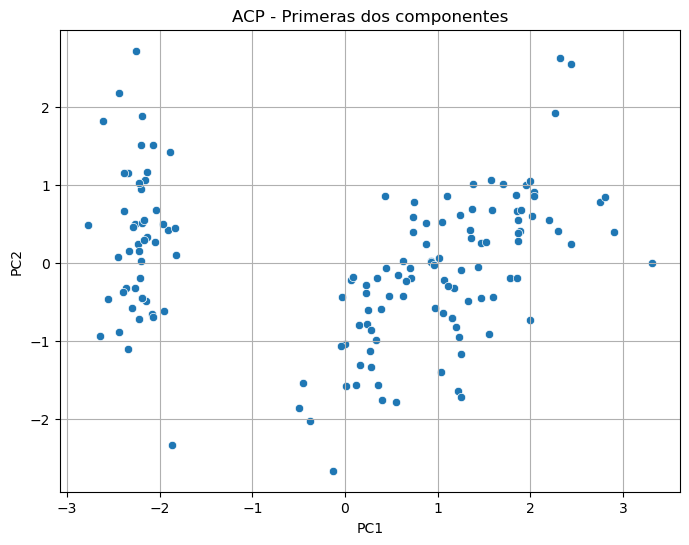

In [31]:
# Visualizar
plt.figure(figsize=(8,6))
sns.scatterplot(x=Xpca[:,0], y=Xpca[:,1])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("ACP - Primeras dos componentes")
plt.grid(True)
plt.show()

In [32]:
# Autovalores
eigenvalues = pca.explained_variance_
eigenvalues

array([2.93035378, 0.92740362])

In [33]:
# Porcentaje de varianza explicada
explained_variance_ratio = pca.explained_variance_ratio_ * 100
explained_variance_ratio

array([72.77045209, 23.03052327])

In [34]:
# Varianza acumulada
cumulative_variance = np.cumsum(explained_variance_ratio)
cumulative_variance

array([72.77045209, 95.80097536])

In [35]:
# Autovectores
eigenvectors = pca.components_
eigenvectors

array([[ 0.52237162, -0.26335492,  0.58125401,  0.56561105],
       [ 0.37231836,  0.92555649,  0.02109478,  0.06541577]])

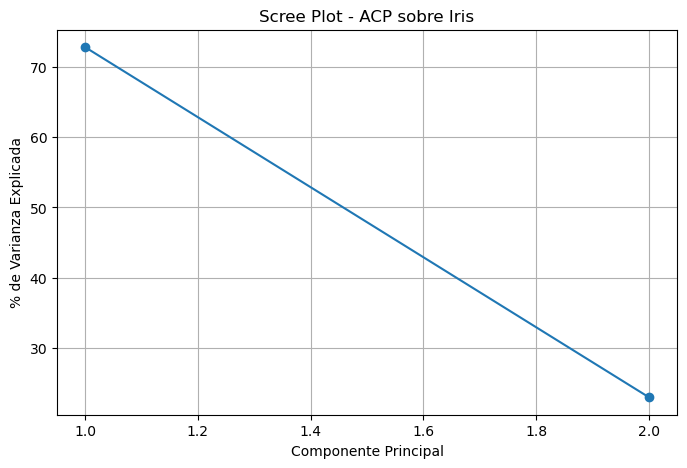

In [36]:
# Scree Plot
plt.figure(figsize=(8,5))
plt.plot(range(1, len(eigenvalues)+1), explained_variance_ratio, marker='o')
plt.title('Scree Plot - ACP sobre Iris')
plt.xlabel('Componente Principal')
plt.ylabel('% de Varianza Explicada')
plt.grid(True)
plt.show()

In [37]:
# cos²: cuadrado de las correlaciones entre variables y componentes
cos2 = eigenvectors**2
cos2

array([[2.72872110e-01, 6.93558114e-02, 3.37856219e-01, 3.19915860e-01],
       [1.38620964e-01, 8.56654824e-01, 4.44989610e-04, 4.27922284e-03]])

In [38]:
# Contribución de cada variable a cada componente (en %)
contrib = (cos2.T * pca.explained_variance_ratio_ * 100).T
contrib

array([[1.98570268e+01, 5.04705375e+00, 2.45859498e+01, 2.32804217e+01],
       [3.19251333e+00, 1.97292089e+01, 1.02483436e-02, 9.85527413e-02]])

In [39]:
# Mostrar cos² de las variables
variables = X.columns
cos2_df = pd.DataFrame(cos2.T, index=variables, columns=[f"PC{i+1}" for i in range(2)])
cos2_df

,PC1,PC2
sepal length,0.272872,0.138621
sepal width,0.069356,0.856655
petal length,0.337856,0.000445
petal width,0.319916,0.004279


In [40]:
# Mostrar contribución de las variables
contrib_df = pd.DataFrame(contrib.T, index=variables, columns=[f"PC{i+1}" for i in range(2)])
contrib_df

,PC1,PC2
sepal length,19.857027,3.192513
sepal width,5.047054,19.729209
petal length,24.585950,0.010248
petal width,23.280422,0.098553


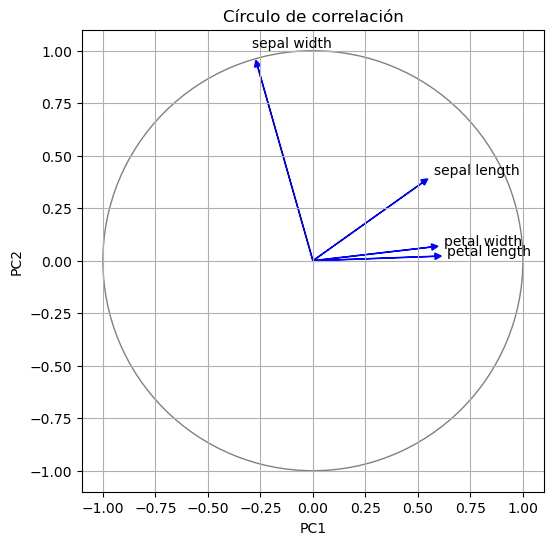

In [41]:
# Círculo de correlación
plt.figure(figsize=(6,6))
for i, var in enumerate(variables):
    plt.arrow(0, 0, eigenvectors[0, i], eigenvectors[1, i],
              head_width=0.03, head_length=0.03, fc='blue', ec='blue')
    plt.text(eigenvectors[0, i]*1.1, eigenvectors[1, i]*1.1, var, color='black')

circle = plt.Circle((0, 0), 1, color='gray', fill=False)
plt.gca().add_artist(circle)
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Círculo de correlación")
plt.grid()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

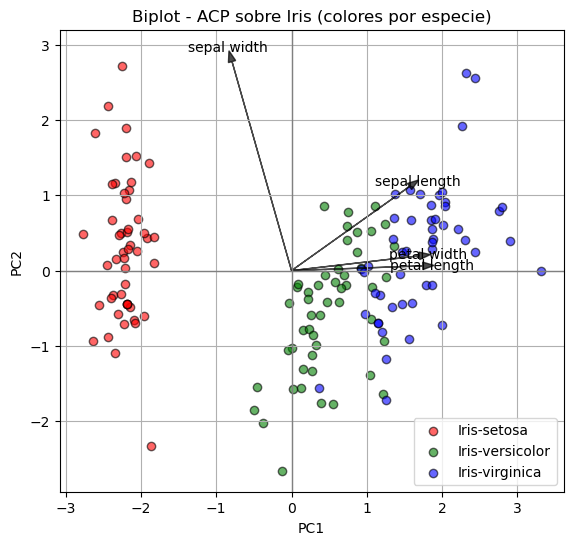

In [42]:
#Individuos+variables

# Crear biplot con colores por especie
plt.figure(figsize=(8, 6))
species_unique = y['class'].unique()
colors = ['red', 'green', 'blue']

for species, color in zip(species_unique, colors):
    idx = y['class'] == species
    plt.scatter(Xpca[idx, 0], Xpca[idx, 1], label=species, color=color, alpha=0.6, edgecolor='k')

# Graficar vectores de variables
variables = X.columns
for i in range(len(variables)):
    plt.arrow(0, 0, eigenvectors[0, i]*3, eigenvectors[1, i]*3,
              color='black', alpha=0.7, head_width=0.1)
    plt.text(eigenvectors[0, i]*3.2, eigenvectors[1, i]*3.2,
             variables[i], color='black', ha='center', va='center')

# Configurar gráfico
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Biplot - ACP sobre Iris (colores por especie)")
plt.grid()
plt.axhline(0, color='gray', lw=1)
plt.axvline(0, color='gray', lw=1)
plt.legend()
plt.gca().set_aspect('equal', adjustable='box')
plt.show()

### Clustering

In [43]:
# KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(Xpca)

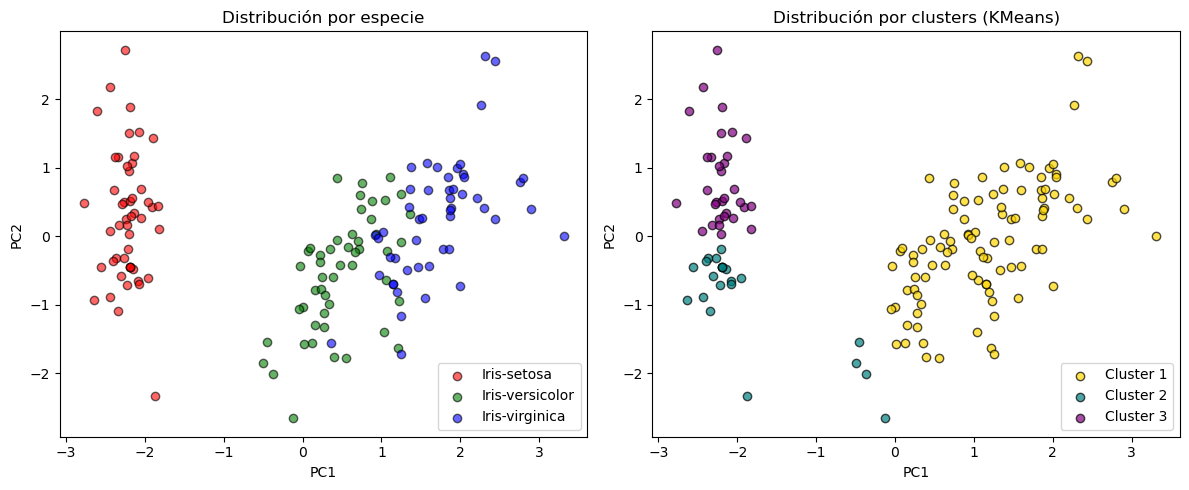

In [44]:
# Graficar
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
species_unique = y['class'].unique()
colors_species = ['red', 'green', 'blue']
colors_clusters = ['gold', 'teal', 'purple']

# Gráfico por especie
for species, color in zip(species_unique, colors_species):
    idx = y['class'] == species
    axs[0].scatter(Xpca[idx, 0], Xpca[idx, 1], label=species, color=color, alpha=0.6, edgecolor='k')
axs[0].set_title("Distribución por especie")
axs[0].set_xlabel("PC1")
axs[0].set_ylabel("PC2")
axs[0].legend()

# Gráfico por cluster con leyenda
for cluster_id, color in enumerate(colors_clusters):
    idx = kmeans_labels == cluster_id
    axs[1].scatter(Xpca[idx, 0], Xpca[idx, 1], label=f"Cluster {cluster_id+1}", color=color, alpha=0.7, edgecolor='k')
axs[1].set_title("Distribución por clusters (KMeans)")
axs[1].set_xlabel("PC1")
axs[1].set_ylabel("PC2")
axs[1].legend()

plt.tight_layout()
plt.show()